In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('ai4i_predictive_maintenance.csv')

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,L70598,L,297.9,307.1,1525,20.3,238,0,0,0,0,0,0
1,2,H76399,H,298.6,307.8,1384,32.3,249,0,0,0,0,0,0
2,3,M37684,M,305.0,314.1,1958,36.3,67,0,0,0,0,0,0
3,4,L78591,L,300.3,309.7,1009,46.8,248,1,0,0,0,1,0
4,5,L87722,L,300.7,311.6,1863,38.6,133,0,0,0,0,0,0


In [5]:
df.shape
df.info()
print(df.describe())
df['Machine failure'].value_counts(normalize=True)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

Machine failure
0    0.9362
1    0.0638
Name: proportion, dtype: float64

10 000 lignes et 14 colonnes, avec 10 000 non-null partout, donc aucune valeur manquante à gérer
2 colonnes texte (Product ID, Type), 3 décimales, 9 entiers
Type (L/M/H) devra être encodé en chiffres avant le modèle

# Visualisationn des pannes

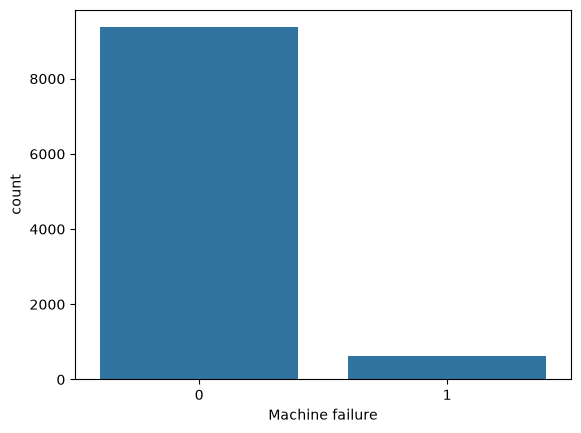

OSF    339
HDF    158
TWF    154
PWF     22
RNF     10
dtype: int64

In [6]:
sns.countplot(x='Machine failure', data=df)
plt.show()

df[['TWF','HDF','PWF','OSF','RNF']].sum().sort_values(ascending=False)

# Comparaison des capteurs entre machines en panne et machines saines

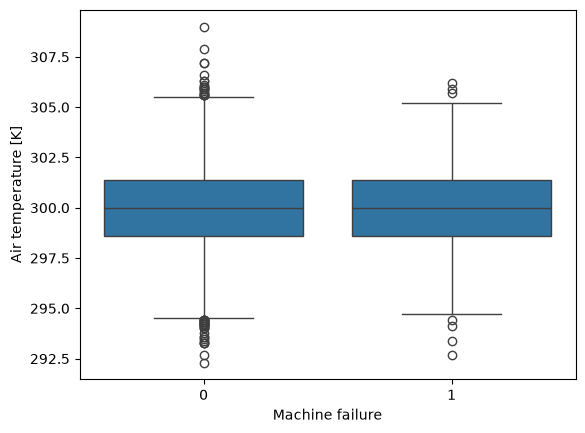

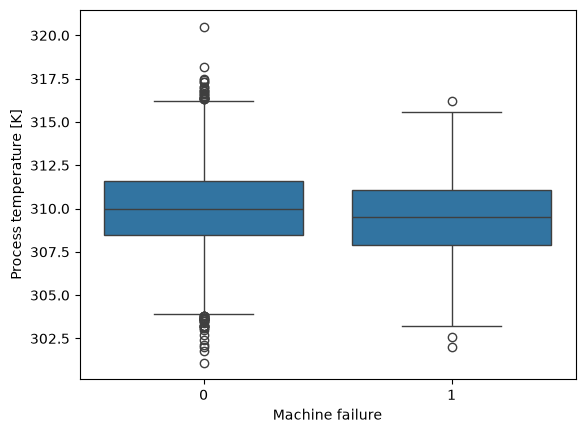

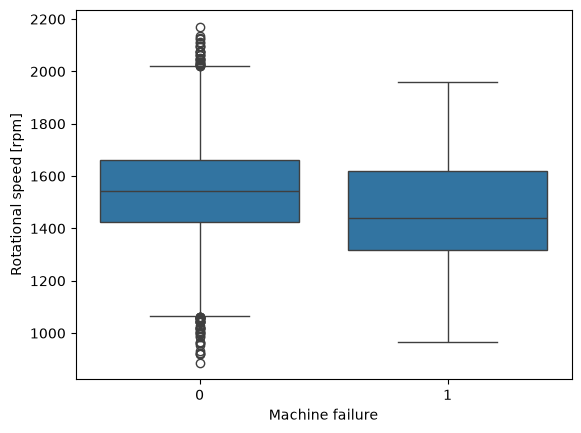

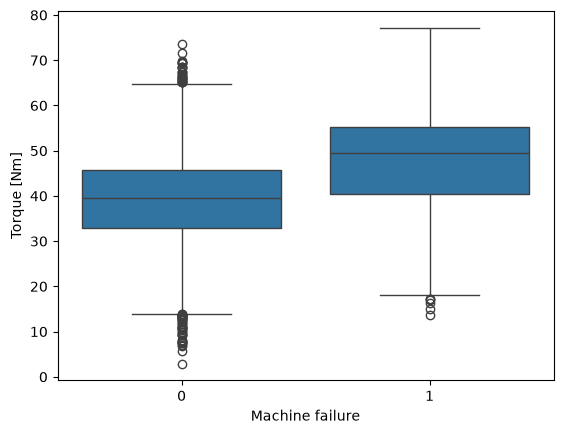

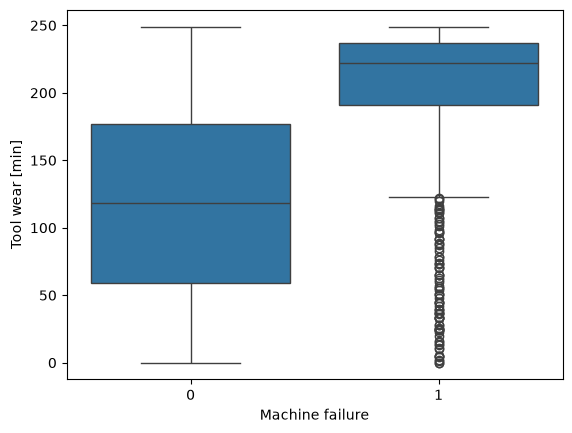

In [7]:
capteurs = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

for c in capteurs:
    sns.boxplot(x='Machine failure', y=c, data=df)
    plt.show()

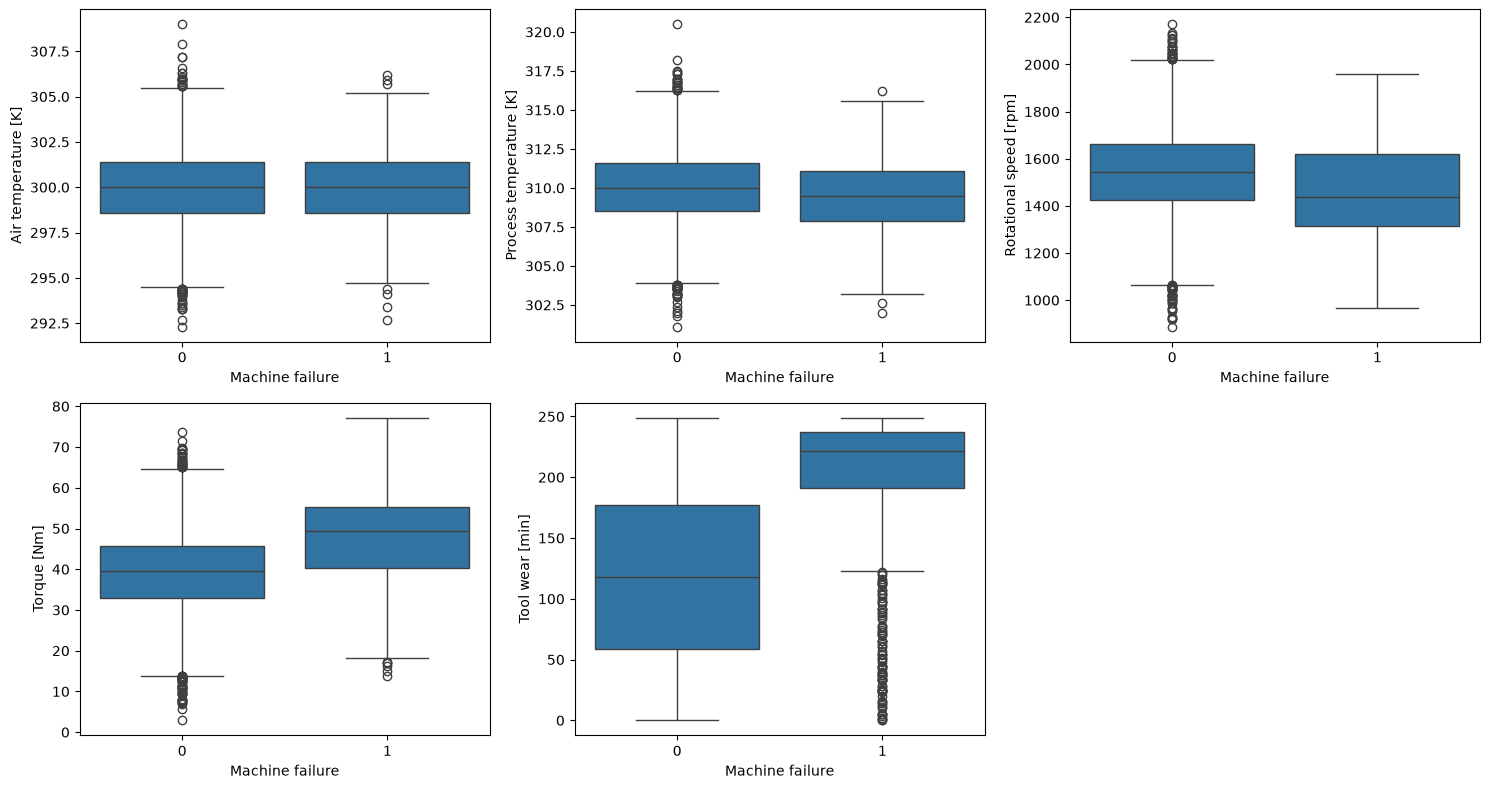

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, c in enumerate(capteurs):
    sns.boxplot(x='Machine failure', y=c, data=df, ax=axes[i])

axes[5].axis('off')
plt.tight_layout()
plt.show()

## Interprétation des boxplots : capteurs selon l'état de la machine

L'analyse compare la distribution de chaque capteur entre les machines
saines (0) et les machines en panne (1).

**Variables peu discriminantes**
- **Température de l'air** : les distributions sont quasiment identiques
  dans les deux groupes. Cette variable apporte peu d'information isolément.
- **Température du procédé** : la médiane est légèrement plus basse pour
  les machines en panne, mais le chevauchement des boîtes reste important.

**Variable modérément discriminante**
- **Vitesse de rotation** : la médiane est plus faible en cas de panne
  (environ 1 420 tr/min contre 1 540 tr/min) et la dispersion est plus
  grande, ce qui suggère que des vitesses atypiques sont associées aux défaillances.

**Variables fortement discriminantes**
- **Couple** : les machines en panne présentent un couple nettement plus
  élevé (médiane d'environ 51 Nm contre 40 Nm).
- **Usure de l'outil** : c'est la variable la plus discriminante, avec une
  médiane d'environ 225 min pour les pannes contre 120 min pour les machines
  saines. Néanmoins, de nombreuses pannes surviennent avec un outil peu usé,
  ce qui indique que l'usure seule ne suffit pas à expliquer les défaillances.

**Conclusion**
L'usure de l'outil et le couple sont les indicateurs individuels les plus
pertinents, ce qui est cohérent avec le mode de panne dominant (OSF, lié au
produit usure × couple). Les valeurs aberrantes sont conservées, car elles
correspondent à des situations réelles et portent une information utile
sur les pannes.

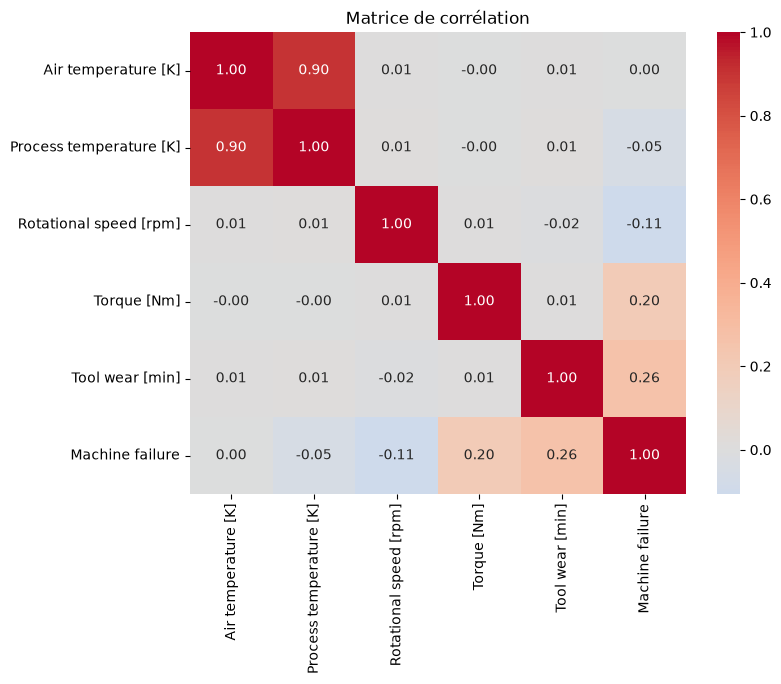

In [9]:
# Matrice de correlation

cols = capteurs + ['Machine failure']
corr = df[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.show()

## Interprétation de la matrice de corrélation

La matrice de corrélation (coefficient de Pearson) mesure l'intensité du lien
linéaire entre les capteurs, et entre chaque capteur et l'état de la machine
(`Machine failure`).

**Corrélations entre les capteurs**
- Les **températures de l'air et du procédé** sont fortement corrélées
  (r ≈ 0,90). Ce résultat est cohérent physiquement : la température du
  procédé dépend en partie de la température ambiante. Cette redondance
  suggère d'utiliser leur **écart** comme variable dérivée, plutôt que de
  les considérer indépendamment.
- Toutes les autres paires de capteurs présentent des corrélations
  proches de zéro (|r| ≤ 0,02) : ces variables sont indépendantes
  les unes des autres.

**Corrélations avec les pannes**
- **Usure de l'outil** (r ≈ 0,26) : lien positif le plus marqué.
- **Couple** (r ≈ 0,20) : lien positif, des couples élevés étant associés
  à davantage de pannes.
- **Vitesse de rotation** (r ≈ -0,11) : lien négatif, des vitesses plus
  faibles étant associées à davantage de pannes.
- **Température du procédé** (r ≈ -0,05) et **température de l'air**
  (r ≈ 0,00) : liens linéaires quasi nuls.

**Limites de l'analyse**
Les coefficients restent faibles (maximum de 0,26). La corrélation de
Pearson ne capte que les relations linéaires, alors que les pannes de ce
jeu de données dépendent surtout de **seuils** et de **combinaisons de
variables** (usure × couple, écart de température, puissance mécanique).
Un faible coefficient n'implique donc pas qu'une variable est inutile.
Par ailleurs, la corrélation n'implique pas la causalité.

**Conclusion et suite**
Ces résultats confirment ceux des boxplots : l'usure de l'outil et le couple
sont les indicateurs les plus liés aux pannes. Ils motivent la création de
variables dérivées lors de la préparation des données :
- `Temp diff` = température du procédé − température de l'air
- `Tool wear × Torque`, en lien avec le mode de panne OSF

In [10]:
# OSF : usure × couple
df['wear_x_torque'] = df['Tool wear [min]'] * df['Torque [Nm]']
print(df.groupby('OSF')['wear_x_torque'].describe())

# HDF : écart de température et vitesse
df['Temp diff'] = df['Process temperature [K]'] - df['Air temperature [K]']
print(df[df['HDF'] == 1][['Temp diff', 'Rotational speed [rpm]']].describe())

# PWF : puissance en watts
df['Power [W]'] = df['Torque [Nm]'] * df['Rotational speed [rpm]'] * 2 * np.pi / 60
df[df['PWF'] == 1]['Power [W]'].describe()

      count          mean          std      min      25%      50%       75%  \
OSF                                                                           
0    9661.0   4693.120588  2949.896291      0.0   2177.4   4448.5   6919.20   
1     339.0  12480.452507  1223.464819  10995.6  11503.6  12233.2  13128.05   

         max  
OSF           
0    12552.0  
1    17248.0  
        Temp diff  Rotational speed [rpm]
count  158.000000              158.000000
mean     8.213924             1274.196203
std      0.370998               85.435151
min      6.500000              965.000000
25%      8.100000             1233.250000
50%      8.300000             1289.000000
75%      8.500000             1342.750000
max      8.600000             1379.000000


count      22.000000
mean     7189.593336
std       492.443988
min      6410.419810
25%      6773.729292
50%      7193.618858
75%      7542.388003
max      8038.791058
Name: Power [W], dtype: float64

In [11]:
print(df['Power [W]'].describe())

hors_plage = (df['Power [W]'] < 3500) | (df['Power [W]'] > 9000)
print(hors_plage.sum())

df[hors_plage]['Machine failure'].value_counts()

count    10000.000000
mean      6427.294547
std       1784.063515
min        467.071052
25%       5201.472125
50%       6345.216054
75%       7593.640469
max      15837.271222
Name: Power [W], dtype: float64
1242


Machine failure
0    1069
1     173
Name: count, dtype: int64

# Preparation des donnees


In [12]:
# nouvelles variables

df_model = df.copy()

df_model['Temp diff [K]'] = df_model['Process temperature [K]'] - df_model['Air temperature [K]']
df_model['Wear x Torque'] = df_model['Tool wear [min]'] * df_model['Torque [Nm]']
df_model['Power [W]'] = df_model['Torque [Nm]'] * df_model['Rotational speed [rpm]'] * 2 * np.pi / 60   # conversion en rad/s

In [13]:
# encodage
df_model['Type'] = df_model['Type'].map({'L': 0, 'M': 1, 'H': 2})

In [14]:
# separation target et features
colonnes_a_retirer = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

X = df_model.drop(columns=colonnes_a_retirer + ['Machine failure'])
y = df_model['Machine failure']

print(X.columns.tolist())
X = X.drop(columns=['wear_x_torque', 'Temp diff'])
print(X.shape)

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'wear_x_torque', 'Temp diff', 'Power [W]', 'Temp diff [K]', 'Wear x Torque']
(10000, 9)


In [15]:
#  decoupage train/test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(8000, 9) (2000, 9)
0.06375 0.064


In [18]:
# baseline (regression logistique)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.fit_transform(X_test)

modele = LogisticRegression(class_weight='balanced', max_iter=1000)
modele.fit(X_train_sc, y_train)

y_pred = modele.predict(X_test_sc)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[1499  373]
 [  25  103]]
              precision    recall  f1-score   support

           0       0.98      0.80      0.88      1872
           1       0.22      0.80      0.34       128

    accuracy                           0.80      2000
   macro avg       0.60      0.80      0.61      2000
weighted avg       0.93      0.80      0.85      2000



In [19]:
df_final = X.copy()
df_final['Machine failure'] = y
df_final.to_csv("donnees_preparees.csv", index=False)